In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

# ### testing
# from scipy import integrate
# from scipy.stats import norm
# from scipy.special import erf, erfinv

In [2]:
N = 64
d = 3

# sigma = 5
# f = utils.gaussian_3d(N, sigma=sigma)
# g = utils.gaussian_3d(N, sigma=sigma)

z = np.linspace(-1, 1, N, endpoint=False)
# z = np.linspace(-(1 - (1/N)), 1 - (1/N), N, endpoint=True) 

f = np.ones((N,N,N))
g = np.ones((N,N,N))

# f = utils.indicator_3d(N)
# g = utils.indicator_3d(N)

f = signals.Signal(f, d=3, dx=1).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=1).preprocess_signals()[0]

print(f.shape)

print(np.sum(f))

(64, 64, 64)
0.9999999999999999


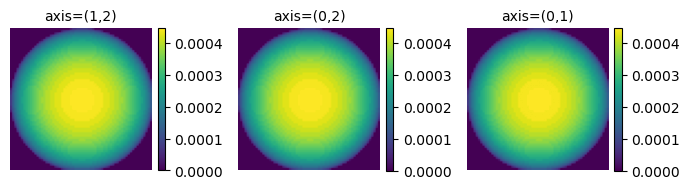

In [3]:
plots.orthogonal_2D_projection_plot(f)
# plots.orthogonal_2D_slice_plot(f)

In [4]:
### EV: Note setting normalize=True
###     this shouldn't matter for a centered Gaussian
###     but the RT is not giving \int = 1 as of now

f_rt = transforms.Transform(f, d=3).radon_transform()[0]
f_cdf = transforms.Transform(f, d=3).cdf_transform(normalize=True)[0]
f_icdf = transforms.Transform(f, d=3).inverse_cdf_transform(normalize=True)[0]

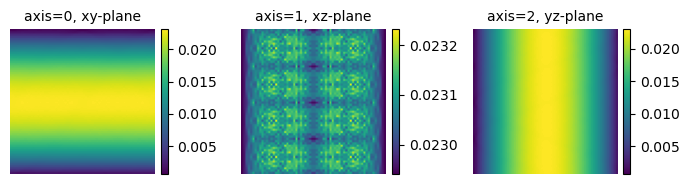

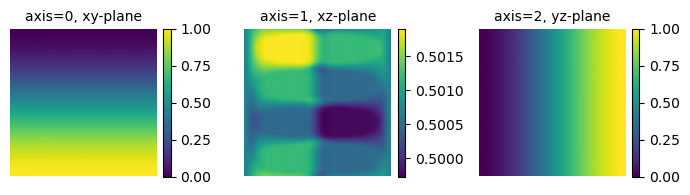

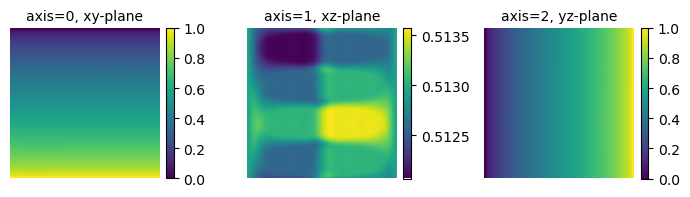

In [5]:
plots.orthogonal_2D_slice_plot(f_rt)
plots.orthogonal_2D_slice_plot(f_cdf)
plots.orthogonal_2D_slice_plot(f_icdf)

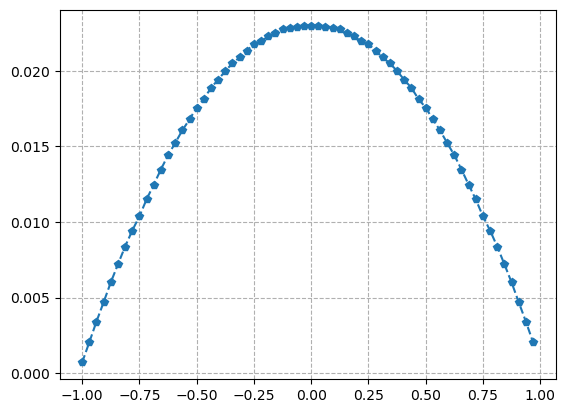

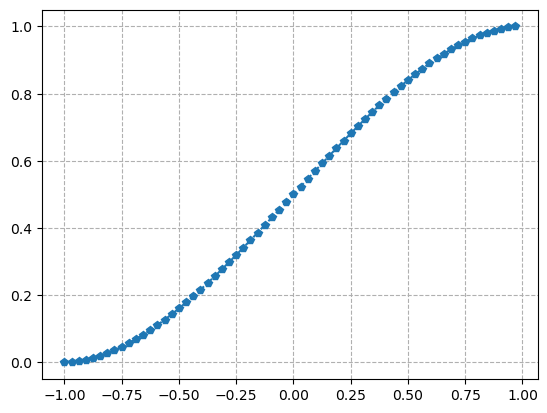

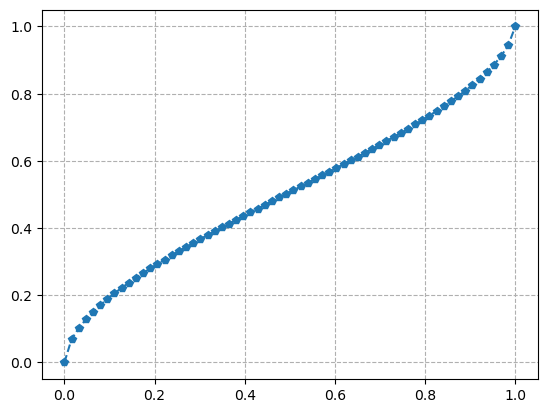

In [6]:
# plt.plot(f_rt[0, :, 0], 'p--')
# plt.grid(which='major', linestyle='--')
# plt.show()
# plt.plot(f_cdf[0, :, 0], 'p--')
# plt.grid(which='major', linestyle='--')
# plt.show()
# plt.plot(f_icdf[0, :, 0], 'p--')
# plt.grid(which='major', linestyle='--')
# plt.show()

### EV: trying to show correct grid
t = np.linspace(0, 1, N, endpoint=True)

plt.plot(z, f_rt[0, :, 0], 'p--')
plt.grid(which='major', linestyle='--')
plt.show()
plt.plot(z, f_cdf[0, :, 0], 'p--')
plt.grid(which='major', linestyle='--')
plt.show()
plt.plot(t, f_icdf[0, :, 0], 'p--')
plt.grid(which='major', linestyle='--')
plt.show()

# plt.plot(f_cdf[0, :, 0], 'p--', label='cdf')
# plt.plot(f_icdf[0, :, 0], 'p--', label='icdf')
# plt.legend()
# plt.grid(which='major', linestyle='--')
# plt.show()

In [7]:
idx=0

f_c = f_cdf[idx, :, idx]
cdf = 3/4 * (z - z**3/3 + 2/3)

# np.isclose(f_c, cdf, atol=1e-3)

In [10]:
# y = np.linspace(0, 1, N, endpoint=True)
# icdf = 2*np.cos(1/3 * np.arccos(1 - 2*y))

In [12]:
# # 3/4*(t-t^3/3 + 2/3) = y
# # t - t^3/3 + 2/3 = 4*y/3
# # t^3 + 4*y - 3*t - 2 = 0
# # t^3 - 3*t + 4*y-2 = 0

# y = 0.8
# c = [1,0,-3,4*y-2]
# np.roots(c)

# y = 0
# c = [1,0,-3,4*y-2]
# np.roots(c)

array([-1.90521644,  1.47949789,  0.42571855])

In [14]:
idx = 0
f_i = f_icdf[idx, :, idx]

ys = np.linspace(0, 1, N, endpoint=True)

icdf = np.zeros(N)

for idx, y in enumerate(ys):
    c = np.array([1, 0, -3, 4*y-2])
    r = np.roots(c)
    icdf[idx] = r[-1]

icdf = (icdf + 1)/2

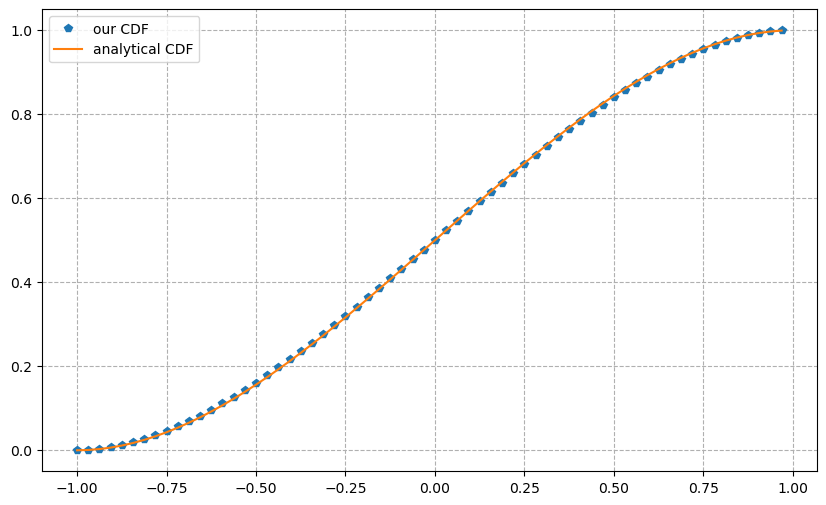

In [15]:
plt.figure(figsize=(10,6))

plt.plot(z, f_c, 'p', label='our CDF')
plt.plot(z, cdf, label='analytical CDF')

plt.legend()
plt.grid(which='major', linestyle='--')
plt.show()

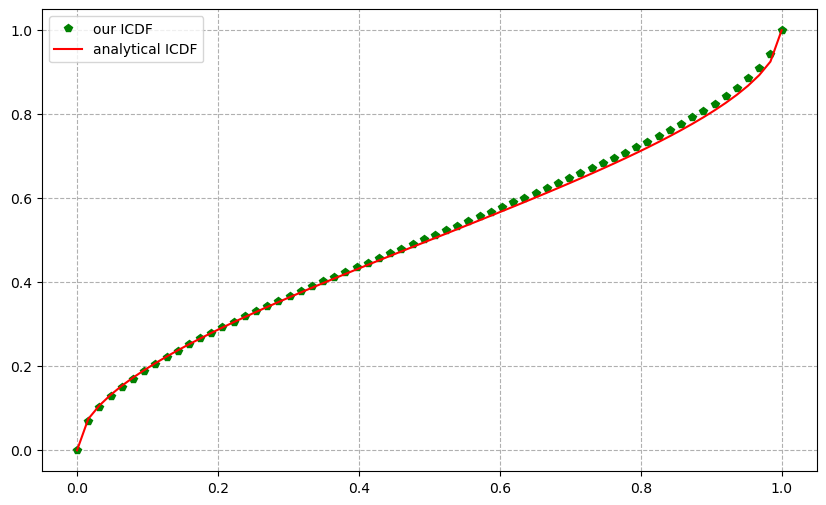

In [16]:
plt.figure(figsize=(10,6))

plt.plot(ys, f_i, 'p', c='g', label='our ICDF')
plt.plot(ys, icdf, c='r', label='analytical ICDF')

plt.legend()
plt.grid(which='major', linestyle='--')
plt.show()

In [17]:
np.linalg.norm(f_i - icdf)

0.07666016308194237

In [ ]:
# plt.figure(figsize=(10,6))
# plt.plot(z, f_c, 'p', label='ours')
# plt.plot(z, cdf, '-', label='analytical')
# plt.legend()
# plt.grid(which='major', linestyle='--')
# plt.show()

In [18]:
# plt.figure(figsize=(10,6))
# plt.plot(f_i, z, 'p-', label='ours')
# # plt.plot(icdf, z, '-', label='analytical')
# plt.legend()
# plt.grid(which='major', linestyle='--')
# plt.show()

In [19]:
# def compute_inverse_cdfs(P, x, u_grid):
#     """
#     Vectorized computation of inverse CDFs for a matrix P.
#     Each column of P is a PDF defined on grid x.
   
#     Parameters:
#       P      : 2D numpy array of shape (len(x), M), with each column a PDF.
#       x      : 1D numpy array of grid points.
#       u_grid : 1D numpy array of values in [0,1] for evaluating the inverse CDF.
     
#     Returns:
#       inv_cdfs: 2D array of shape (len(u_grid), M) where each column is the inverse CDF.
#     """
    
#     dx = x[1] - x[0]
#     # Normalize each column (if not already normalized)
#     P_norm = P / (np.sum(P, axis=0) * dx)
#     # Compute the CDFs along axis=0 (each column)
#     CDF = np.cumsum(P_norm, axis=0) * dx
#     # Normalize each column's CDF so that the last entry is 1
#     CDF = CDF / CDF[-1, :]
   
#     ny, nx = CDF.shape
#     cp = u_grid.size
    
#     ICDF = np.zeros((cp, nx))
    
#     for idx in range(nx):
#         # We set bounds_error=False and force fill_value=(x[0], x[-1]) so that u=0,1 map to x[0], x[-1].
#         interpolator = interp1d(CDF[:, idx], x, axis=0, bounds_error=False, fill_value=(x[0], x[-1]), assume_sorted=True)
#         ICDF[:, idx] = interpolator(u_grid)   
    
#     return ICDF



# def clenshaw_curtis(n):
#     """
#     Compute Clenshaw-Curtis nodes and weights for integration on [0,1].
   
#     This function first computes Chebyshev nodes on [-1,1] using
#        x_i = cos(pi * i/(n-1)), i=0,..., n-1,
#     then transforms them to [0,1] via
#        u = (1 - x)/2.
#     The weights are computed using a standard algorithm.
   
#     Parameters:
#       n : int, number of nodes (n >= 2)
     
#     Returns:
#       u : 1D numpy array of nodes in [0,1] (nonuniform, clustering near 0 and 1)
#       w : 1D numpy array of quadrature weights (summing to 1)
#     """
    
#     if n < 2:
#         raise ValueError("n must be at least 2")
#     k = np.arange(n)
#     theta = np.pi * k / (n - 1)
#     x_cc = np.cos(theta)       # nodes on [-1,1]
#     u = (1 - x_cc) / 2         # transform to [0,1]
   
#     w = np.zeros(n)
#     if (n - 1) % 2 == 0:
#         m = (n - 1) // 2
#         for i in range(n):
#             s = 0.0
#             for j in range(1, m):
#                 s += 2 * np.cos(2 * j * theta[i]) / (4 * j**2 - 1)
#             s += np.cos(2 * m * theta[i]) / (4 * m**2 - 1)
#             w[i] = 2 / (n - 1) * (1 - s)
#     else:
#         m = (n - 1) // 2
#         for i in range(n):
#             s = 0.0
#             for j in range(1, m + 1):
#                 s += 2 * np.cos(2 * j * theta[i]) / (4 * j**2 - 1)
#             w[i] = 2 / (n - 1) * (1 - s)
#     # These weights integrate on [-1,1] to 2, so divide by 2 to get integration over [0,1].
#     w = w / 2
    
#     return u, w



# def average_squared_L2_distance_vectorized(P1, P2, x, num_cc=1000):
#     """
#     Compute the average squared L2 distance between inverse CDFs (quantile functions)
#     for corresponding columns of P1 and P2 in a fully vectorized manner.
   
#     For each column (each a PDF on grid x), we:
#       1. Normalize the PDF.
#       2. Compute its inverse CDF on a nonuniform grid u in [0,1] using Clenshaw-Curtis nodes,
#          which cluster near 0 and 1 (capturing steep behavior in the tails).
#       3. Compute the squared difference between the inverse CDFs for P1 and P2,
#          and integrate using the Clenshaw-Curtis quadrature weights.
#       4. Average the squared L2 distances over all columns.
   
#     Parameters:
#       P1, P2 : numpy arrays of shape (len(x), M), where each column is a PDF.
#       x      : 1D numpy array of grid points (assumed uniformly spaced).
#       num_cc : number of Clenshaw-Curtis nodes (default 1000).
     
#     Returns:
#       avg_sq_dist : average squared L2 distance between the inverse CDFs.
#       col_sq_dist : 1D numpy array (length M) of the squared L2 distances per column.
#     """
    
#     dx = x[1] - x[0]
#     # Get Clenshaw-Curtis nodes and weights on [0,1]
#     u_cc, w_cc = clenshaw_curtis(num_cc)  # u_cc: shape (num_cc,), w_cc: shape (num_cc,)
   
#     # Compute vectorized inverse CDFs for P1 and P2 (each shape: (num_cc, M))
#     inv_cdfs1 = compute_inverse_cdfs(P1, x, u_cc)
#     inv_cdfs2 = compute_inverse_cdfs(P2, x, u_cc)
   
#     # Compute squared difference (shape: (num_cc, M))
#     diff_sq = (inv_cdfs1 - inv_cdfs2) ** 2
#     # Integrate along the u-axis using Clenshaw-Curtis weights (broadcast weights to all columns)
#     col_sq_dist = np.sum(diff_sq * w_cc[:, np.newaxis], axis=0)
   
#     avg_sq_dist = np.sqrt(np.mean(col_sq_dist))
    
#     return avg_sq_dist